# Experimental data characterization for CO₂ forecasting

**Applied Computing | Transformer forecasting challenge**

Eight pilot-plant experiments provide process measurements and sequential CO₂ analyzer readings at six absorber locations. This notebook quantifies the sampling structure, spatial and temporal concentration variation, and differences in operating conditions between experiments. The findings inform sequence construction, observation encoding, target treatment, and experiment-level validation.

## 1. Experimental inventory and recording cadence

The eight experiments contain **898 logged records**, with **50–228 records per run**. Successive timestamps are separated by approximately **43–44 seconds**. The nearly constant cadence supports a common time-step representation, but the experiments have different durations and represent separate operating trajectories. Forecast sequences must therefore be constructed **within individual runs**, not across concatenated experiment boundaries.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA
from sklearn.metrics import pairwise_distances

RUNS = ['140120_1','140206_1','140207_1','140207_2','140214_1','140214_2','140227_1','140313_1']
TEST_RUN = '140207_1'  # Reserved for final model evaluation; descriptive projection only here.
DATA_DIR = Path('data/raw')
if not DATA_DIR.exists() and Path('../data/raw').exists():
    DATA_DIR = Path('../data/raw')
DATA_DIR = DATA_DIR.expanduser().resolve()
OUT = Path('outputs/data_exploration') if Path('data/raw').exists() else Path('../outputs/data_exploration')
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi':115,'savefig.dpi':180,'font.size':10,
                     'axes.spines.top':False,'axes.spines.right':False})

def figure(name, fig):
    fig.tight_layout()
    fig.savefig(OUT / f'{name}.png', bbox_inches='tight')
    plt.show()

def load_run(path):
    raw = pd.read_excel(path, sheet_name=0)
    raw.columns = [str(c).strip() for c in raw.columns]
    tc = next((c for c in raw if c.lower() in ('timestamp','time','unnamed: 0')), raw.columns[0])
    stamps = pd.to_datetime(raw[tc], errors='coerce')
    # The first non-timestamp record is normally the units row.
    frame = raw.loc[stamps.notna()].copy().reset_index(drop=True)
    frame = frame.rename(columns={tc:'timestamp'})
    frame['timestamp'] = stamps.loc[stamps.notna()].to_numpy()
    for col in frame.columns.drop('timestamp'):
        frame[col] = pd.to_numeric(frame[col], errors='coerce')
    label_cols = [c for c in frame if c.lower() == 'label']
    co2_cols = [c for c in frame if re.search(r'AT400', c, re.I)]
    if len(label_cols) != 1 or len(co2_cols) != 1:
        raise ValueError(f'{path.name}: expected one label and one AT400 channel; found {label_cols}, {co2_cols}')
    frame['location'] = frame[label_cols[0]]
    frame['co2'] = frame[co2_cols[0]]
    frame['experiment'] = path.stem
    if not frame.timestamp.is_monotonic_increasing:
        raise ValueError(f'{path.name}: timestamps are not chronological')
    return frame, len(raw)-len(frame), co2_cols[0]

experiments, metadata = {}, []
for run in RUNS:
    path = DATA_DIR / (run + '.xlsx')
    if not path.exists():
        raise FileNotFoundError(f'Missing {path}; DATA_DIR={DATA_DIR}')
    frame, excluded, co2_name = load_run(path)
    experiments[run] = frame
    delta = frame.timestamp.diff().dt.total_seconds().dropna()
    metadata.append({'experiment':run, 'partition':'reserved test' if run==TEST_RUN else 'development',
                     'rows':len(frame), 'duration_min':(frame.timestamp.iloc[-1]-frame.timestamp.iloc[0]).total_seconds()/60,
                     'median_interval_s':delta.median(), 'min_interval_s':delta.min(), 'max_interval_s':delta.max(),
                     'duplicate_timestamps':int(frame.timestamp.duplicated().sum()),
                     'invalid_labels':int((~frame.location.between(1,6)).sum()),
                     'missing_CO2':int(frame.co2.isna().sum()), 'excluded_non_time_rows':excluded})
inventory = pd.DataFrame(metadata)
display(inventory.round(2))
inventory.to_csv(OUT/'experiment_inventory.csv',index=False)
print('Total process records:',int(inventory.rows.sum()))
print('Analyzer column:',co2_name)

assert inventory['duplicate_timestamps'].eq(0).all(), 'Duplicate timestamps detected'
assert inventory['invalid_labels'].eq(0).all(), 'Invalid location labels detected'


,experiment,partition,rows,duration_min,median_interval_s,min_interval_s,max_interval_s,duplicate_timestamps,invalid_labels,missing_CO2,excluded_non_time_rows
0,140120_1,development,117,83.53,43.0,43.0,44.0,0,0,0,1
1,140206_1,development,50,35.28,43.0,43.0,44.0,0,0,0,1
2,140207_1,reserved test,118,84.23,43.0,43.0,44.0,0,0,0,1
3,140207_2,development,50,35.28,43.0,43.0,44.0,0,0,0,1
4,140214_1,development,67,47.52,43.0,43.0,44.0,0,0,0,1
5,140214_2,development,50,35.27,43.0,43.0,44.0,0,0,0,1
6,140227_1,development,218,156.23,43.0,43.0,44.0,0,0,0,1
7,140313_1,development,228,163.45,43.0,43.0,44.0,0,0,0,1


Total process records: 898
Analyzer column: AT400


**Interpretation.** Consistent logger spacing does not imply equal amounts of independent information: a longer experiment contributes more temporally correlated records. The run inventory provides the basis for defining valid sequence windows and for comparing model performance at the experiment level, rather than allowing longer runs to dominate a pooled summary.

## 2. Rotating analyzer and observation coverage

The CO₂ analyzer samples one absorber location at a time. Contiguous records with the same location label form a **sampling block**, not simultaneous observations at multiple locations. The block-level summary shows how many logger records occur during each visit, while the per-run location counts reveal unequal observed-target coverage. This structure requires **location-specific availability masks and measurement ages** for causal concentration histories.

Across the eight experiments, the segmentation identifies **53 distinct analyzer visits per sampling location**. Each visit can include multiple consecutive logger records; those records are temporally correlated and should not be interpreted as independent concentration measurements. The distinction is important when assessing effective target coverage and constructing history windows.

location,L1,L2,L3,L4,L5,L6,total
experiment,,,,,,,
140120_1,21,21,21,14,19,21,117
140206_1,9,9,9,6,9,8,50
140207_1,21,21,21,15,19,21,118
140207_2,9,9,9,6,8,9,50
140214_1,12,12,12,8,11,12,67
140214_2,9,8,9,6,9,9,50
140227_1,39,39,39,28,34,39,218
140313_1,39,39,39,26,35,50,228


,blocks,median_records_per_block
location,,
1,53,3.0
2,53,3.0
3,53,3.0
4,53,2.0
5,53,3.0
6,53,3.0


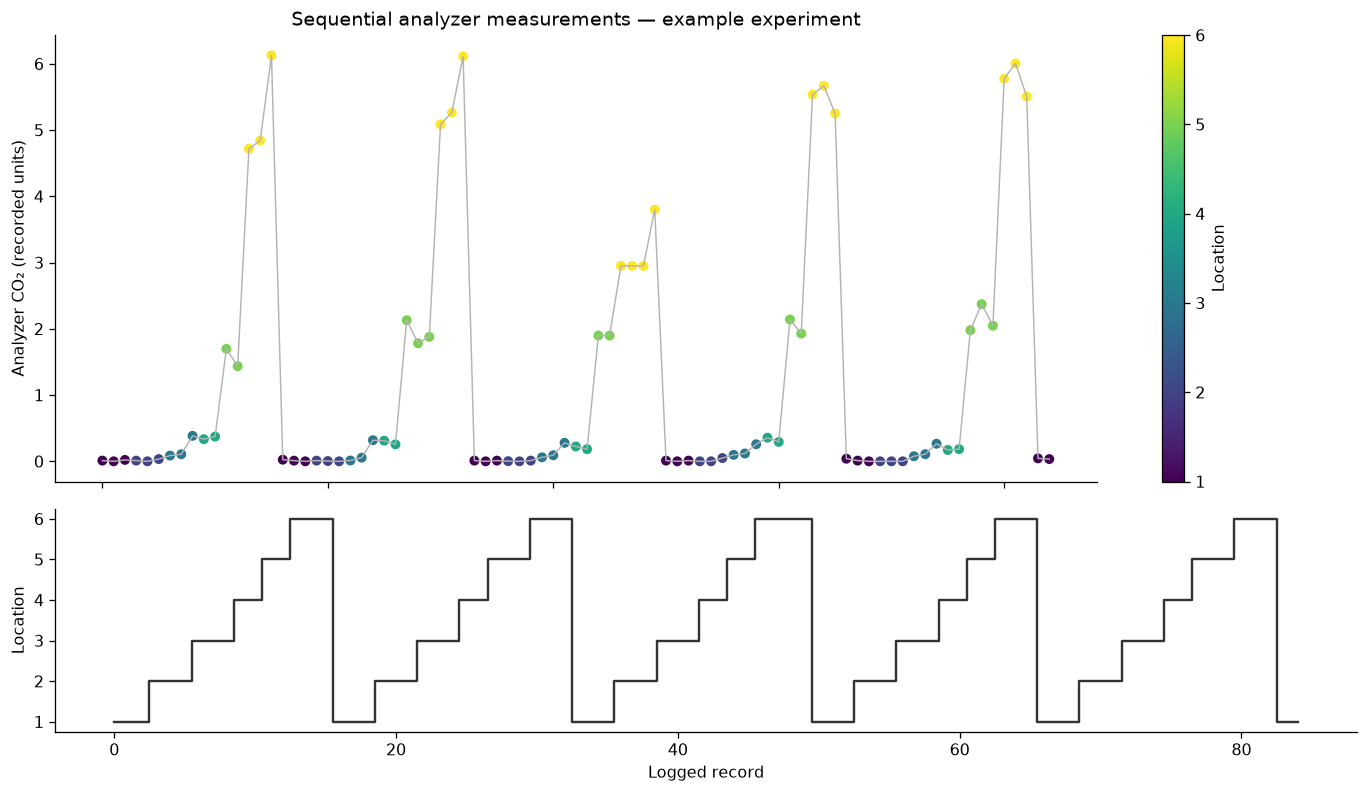

In [2]:
valid = pd.concat(experiments.values(), ignore_index=True)
valid = valid.loc[valid.location.between(1,6) & np.isfinite(valid.co2)].copy()
valid['location'] = valid.location.astype(int)
valid = valid.sort_values(['experiment','timestamp']).reset_index(drop=True)
valid['block_start'] = valid.groupby('experiment').location.transform(lambda s: s.ne(s.shift()))
valid['block_id'] = valid.groupby('experiment').block_start.cumsum()
blocks = (valid.groupby(['experiment','block_id'],as_index=False)
          .agg(location=('location','first'),start=('timestamp','min'),end=('timestamp','max'),
               n_records=('co2','size'),co2_median=('co2','median')))
counts=valid.groupby(['experiment','location']).size().unstack(fill_value=0).reindex(index=RUNS,columns=range(1,7),fill_value=0)
block_summary=blocks.groupby('location').agg(blocks=('n_records','size'),median_records_per_block=('n_records','median'))
display(counts.rename(columns=lambda k:f'L{k}').assign(total=counts.sum(axis=1)))
display(block_summary)
fig,axes=plt.subplots(2,1,figsize=(12,7),sharex=True,gridspec_kw={'height_ratios':[2,1]})
seg=valid.loc[valid.experiment=='140313_1'].head(85).copy()
ix=np.arange(len(seg))
axes[0].plot(ix,seg.co2,color='0.7',lw=0.9)
sc=axes[0].scatter(ix,seg.co2,c=seg.location,cmap='viridis',vmin=1,vmax=6,s=27)
axes[0].set(ylabel='Analyzer CO₂ (recorded units)',title='Sequential analyzer measurements — example experiment')
axes[1].step(ix,seg.location,where='mid',color='0.2')
axes[1].set(xlabel='Logged record',ylabel='Location',yticks=range(1,7))
fig.colorbar(sc,ax=axes[0],ticks=range(1,7),label='Location')
figure('01_sampling_sequence',fig)
blocks.to_csv(OUT/'sampling_blocks.csv',index=False)

**Interpretation.** The reserved experiment contains 21 recorded observations each at L1, L2, L3 and L6, compared with 15 at L4 and 19 at L5. Thus, even within a single run, supervision is uneven across locations. Model targets should distinguish directly observed concentrations from reconstructed values. The documented analyzer carryover at L1 additionally warrants its special treatment under the source paper's reconstruction convention.

## 3. Spatial concentration variation

The observed concentration distributions differ sharply by absorber location. L2 values are often close to zero, whereas L6, at the gas inlet, has much larger readings. The boxplots show location-wise spread; the heatmap shows how **observed median concentrations** vary across both experiments and locations. A logarithmic display makes low-concentration regions visible without changing the underlying measurements.

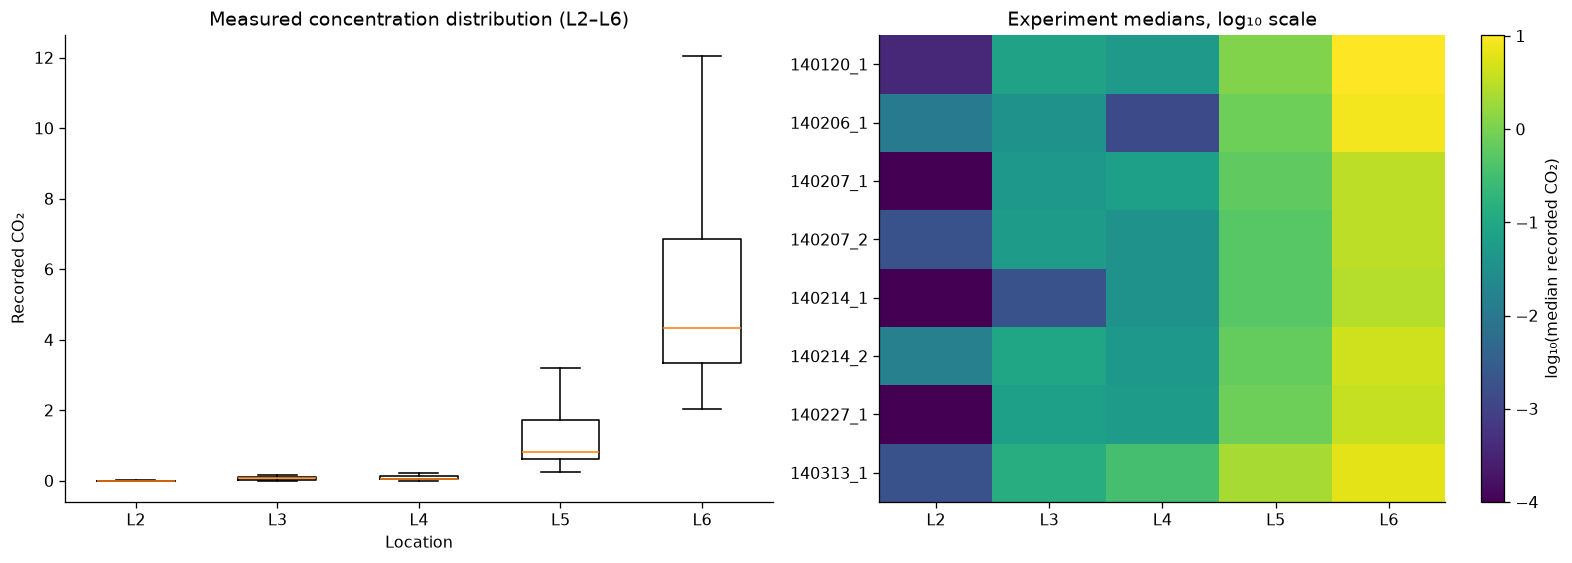

,experiment,location,count,median,std,min,max
0,140120_1,1,21,0.1547,0.1932,0.0016,0.5433
1,140120_1,2,21,0.0004,0.0146,0.0000,0.0673
2,140120_1,3,21,0.0778,0.0503,0.0124,0.1621
3,140120_1,4,14,0.0515,0.0311,0.0018,0.1199
4,140120_1,5,19,1.1434,0.7149,0.2625,3.1641
5,140120_1,6,21,10.2044,0.9229,8.0216,12.0367
6,140206_1,1,9,0.0357,0.0293,0.0018,0.0899
7,140206_1,2,9,0.0124,0.0305,0.0000,0.0973
8,140206_1,3,9,0.0380,0.0394,0.0018,0.1199
9,140206_1,4,6,0.0013,0.0017,0.0000,0.0047


In [3]:
summary=valid.groupby(['experiment','location']).co2.agg(['count','median','std','min','max']).reset_index()
med=summary.pivot(index='experiment',columns='location',values='median').reindex(RUNS)
fig,axes=plt.subplots(1,2,figsize=(14,5))
for k in range(2,7):
    z=valid.loc[valid.location==k,'co2'].dropna()
    axes[0].boxplot([z],positions=[k],widths=.55,showfliers=False)
axes[0].set(xticks=range(2,7),xticklabels=[f'L{k}' for k in range(2,7)],xlabel='Location',ylabel='Recorded CO₂',title='Measured concentration distribution (L2–L6)')
im=axes[1].imshow(np.log10(med.loc[:,2:6].clip(lower=1e-4)),aspect='auto',cmap='viridis')
axes[1].set(xticks=range(5),xticklabels=[f'L{k}' for k in range(2,7)],yticks=range(8),yticklabels=RUNS,title='Experiment medians, log₁₀ scale')
fig.colorbar(im,ax=axes[1],label='log₁₀(median recorded CO₂)')
figure('02_spatial_and_experiment_concentrations',fig)
display(summary.round(4)); summary.to_csv(OUT/'concentration_summary.csv',index=False)

**Interpretation.** The median observed L6 concentration is approximately **10.20** in `140120_1` and **3.17** in `140207_1` (recorded units), illustrating substantial between-run variation even at the same sampling point. These scale differences support **location-aware outputs and per-location error reporting**. They also caution against relying on percentage errors near zero or interpreting a pooled raw-scale error without checking which locations dominate it.

## 4. Temporal variation between analyzer visits

To measure how concentrations evolve between genuinely new observations, each contiguous location block is represented by its median reading. The analysis compares **successive blocks at the same location within the same experiment**, reporting both the elapsed time and the absolute change in concentration. This avoids confusing repeated logger records within one analyzer visit with independent revisits.

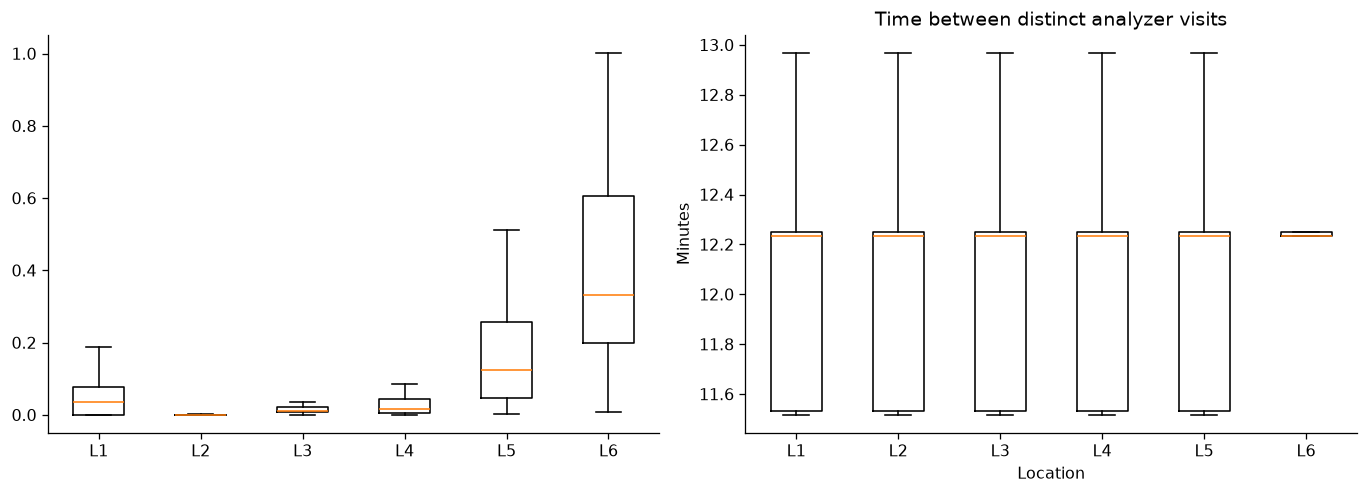

,n,median_abs_change,p90_abs_change,median_revisit_min
location,,,,
1,45,0.035,0.119,12.233
2,45,0.000,0.010,12.233
3,45,0.011,0.035,12.233
4,45,0.016,0.114,12.233
5,45,0.123,0.658,12.233
6,45,0.331,1.471,12.233


In [4]:
b=blocks.sort_values(['experiment','location','start']).copy()
b['previous_co2']=b.groupby(['experiment','location']).co2_median.shift()
b['previous_start']=b.groupby(['experiment','location']).start.shift()
b['abs_change']=(b.co2_median-b.previous_co2).abs()
b['revisit_min']=(b.start-b.previous_start).dt.total_seconds()/60
revisits=b.dropna(subset=['abs_change','revisit_min'])
fig,axes=plt.subplots(1,2,figsize=(12,4.4))
for j,col in enumerate(['abs_change','revisit_min']):
    vals=[revisits.loc[revisits.location==k,col].to_numpy() for k in range(1,7)]
    axes[j].boxplot(vals,tick_labels=[f'L{k}' for k in range(1,7)],showfliers=False)
axes[j].set(xlabel='Location',ylabel='Absolute change (recorded CO₂ units)',title='Change between distinct analyzer visits')
axes[1].set(xlabel='Location',ylabel='Minutes',title='Time between distinct analyzer visits')
figure('03_block_revisit_dynamics',fig)
change_stats=revisits.groupby('location').agg(n=('abs_change','size'),median_abs_change=('abs_change','median'),p90_abs_change=('abs_change',lambda x:x.quantile(.9)),median_revisit_min=('revisit_min','median'))
display(change_stats.round(3)); change_stats.to_csv(OUT/'block_revisit_summary.csv')

**Interpretation.** The median same-location revisit interval is approximately **12.23 minutes**, compared with a logger interval of about 43 seconds. An 18-record history covers roughly **12.9 minutes**, close to one analyzer cycle, but the latest observation at each location can still have a different age. Median absolute changes between visits also vary by location—approximately **0.011** at L3, **0.123** at L5, and **0.331** at L6 (recorded units). These results provide an empirical basis for testing history lengths around one sampling cycle and for encoding **observation age separately for each location**.

## 5. Physically interpretable operating conditions

The source study characterizes absorber operation using the **liquid-to-gas volumetric flow ratio (L/G)** and gas-inlet CO₂ concentration. Here, L/G is calculated from the supplied mechanistic implementation: `FT103` gives liquid mass flow; `FT301` and `FT303` give the CO₂ and N₂ inlet streams, corrected using the specified pressure and temperature channels. The calculation converts the engineering units to consistent volumetric-flow units.

The operating map pairs each **observed L6 concentration** with the L/G value at its timestamp. Unlike a sensor-by-sensor plot, these coordinates have direct process meaning: they describe solvent-to-gas loading and inlet gas composition. Their overlap across runs informs whether differences between experiments are evident in these primary operating variables.

,n,valid_flow,median_L_over_G,min_L_over_G,max_L_over_G,median_liquid_m3h,median_gas_m3h
experiment,,,,,,,
140120_1,117,117,0.0094,0.0070,0.0107,0.2531,26.8596
140206_1,50,50,0.0091,0.0086,0.0107,0.2504,27.5556
140207_1,118,118,0.0041,0.0035,0.0050,0.2533,62.7611
140207_2,50,50,0.0050,0.0041,0.0053,0.2976,59.7109
140214_1,67,67,0.0050,0.0042,0.0055,0.2976,59.4980
140214_2,50,49,0.0052,0.0050,0.0056,0.2953,56.2701
140227_1,218,218,0.0040,0.0037,0.0048,0.2108,53.2747
140313_1,228,228,0.0046,0.0044,0.0049,0.2491,54.2694


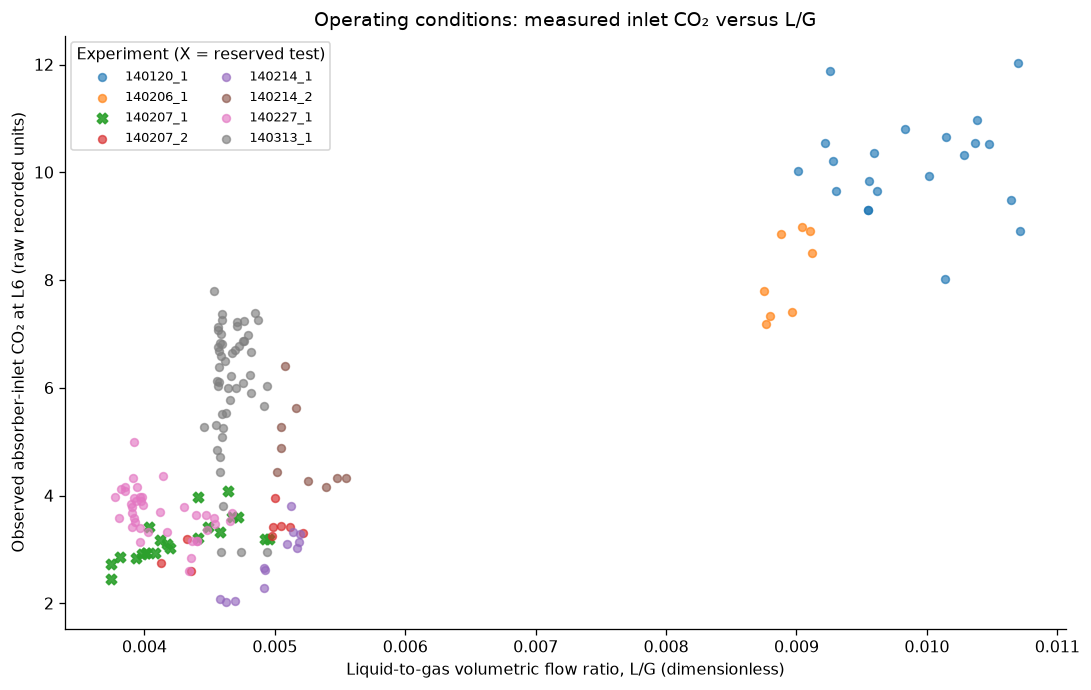

L6 observed records used for operating-condition scatter: 169
Note: L6 is observed intermittently; no reconstructed values are used.


In [5]:
# Reconstruct the flow ratio from results_generation.m and steady_state.xlsx.
# Source: MATLAB input_df(:,7)=FT103, (:,17)=FT301, (:,19)=FT303,
# (:,31)=PT110, (:,36)=PT402, (:,37)=PT403,
# (:,43)=TT107, (:,76)=TT304, (:,87)=TT410.
FLOW = ['FT103','FT301','FT303','PT110','PT402','PT403','TT107','TT304','TT410']
missing_by_run = {run: [c for c in FLOW if c not in experiments[run].columns]
                  for run in RUNS}
missing_by_run = {run: cols for run, cols in missing_by_run.items() if cols}
if missing_by_run:
    raise ValueError(f'Missing required physical-flow channels: {missing_by_run}. '
                     'Inspect raw workbook headers before changing any mappings.')

# Raw workbooks store engineering units in a non-data header row. Read those
# strings to avoid silently confusing kelvin and Celsius temperatures.
def raw_unit_map(run):
    raw = pd.read_excel(DATA_DIR / f'{run}.xlsx', sheet_name=0, nrows=3)
    raw.columns = [str(c).strip() for c in raw.columns]
    first = raw.iloc[0]
    return {c: str(first.get(c, '')).strip() for c in FLOW}

unit_by_run = {r: raw_unit_map(r) for r in RUNS}
# Units are validated below; no separate units table is displayed.

def temperature_kelvin(series, unit, channel):
    import re

    u = str(unit).strip().lower()
    u = u.replace('°', '').replace('degrees', '')
    u = re.sub(r'[\s()\[\]{}]', '', u)
    u = u.replace('0c', 'c')

    if u in {'k', 'kelvin'}:
        return series.astype(float)

    if u in {'c', 'degc', 'celsius', 'oc', 'nan', 'none', ''}:
        return series.astype(float) + 273.15

    raise ValueError(
        f'Unexpected temperature unit for {channel}: {unit!r}'
    )
RHO_L = 1004.0  # kg/m^3, original mechanistic model
ATM_BAR = 1.013  # bar, same convention as results_generation.m
physical_frames = []
for run in RUNS:
    df = experiments[run].copy()
    u = unit_by_run[run]
    t_g = temperature_kelvin(df['TT107'],u['TT107'],'TT107')
    t_co2 = temperature_kelvin(df['TT410'],u['TT410'],'TT410')
    t_n2 = temperature_kelvin(df['TT304'],u['TT304'],'TT304')
    p_bottom = df['PT110'] + ATM_BAR
    p_co2 = df['PT402'] + ATM_BAR
    p_n2 = df['PT403'] + ATM_BAR
    liquid_m3h = df['FT103'] / RHO_L
    gas_m3h = (df['FT301'] * (p_co2/p_bottom) * (t_g/t_co2)
               + df['FT303'] * (p_n2/p_bottom) * (t_g/t_n2))
    valid_physics = (p_bottom.gt(0) & p_co2.gt(0) & p_n2.gt(0)
                     & t_g.gt(0) & t_co2.gt(0) & t_n2.gt(0)
                     & liquid_m3h.gt(0) & gas_m3h.gt(0)
                     & np.isfinite(liquid_m3h) & np.isfinite(gas_m3h))
    df['liquid_m3h'] = liquid_m3h.where(valid_physics)
    df['gas_m3h'] = gas_m3h.where(valid_physics)
    df['L_over_G'] = (liquid_m3h/gas_m3h).where(valid_physics)
    physical_frames.append(df)

physical = pd.concat(physical_frames, ignore_index=True)
flow_summary = physical.groupby('experiment').agg(
    n=('L_over_G','size'), valid_flow=('L_over_G','count'),
    median_L_over_G=('L_over_G','median'),
    min_L_over_G=('L_over_G','min'), max_L_over_G=('L_over_G','max'),
    median_liquid_m3h=('liquid_m3h','median'),
    median_gas_m3h=('gas_m3h','median'))
display(flow_summary.round(4))
flow_summary.to_csv(OUT/'physical_operating_flow_summary.csv')
if flow_summary.valid_flow.eq(0).any():
    raise ValueError('At least one experiment has no valid flow-ratio records; check source units.')

# Paper Fig. 3-inspired comparison: use observed L6 readings only.
l6 = physical.loc[(physical.location == 6) & physical.co2.notna()
                  & physical.L_over_G.notna()].copy()
if l6.empty:
    raise ValueError('No physically observed L6 points with valid L/G ratio.')
fig, ax = plt.subplots(figsize=(9.6,6.1))
for run in RUNS:
    d = l6.loc[l6.experiment.eq(run)]
    if d.empty: continue
    ax.scatter(d.L_over_G, d.co2, s=43 if run==TEST_RUN else 24,
               alpha=.90 if run==TEST_RUN else .65,
               marker='X' if run==TEST_RUN else 'o', label=run)
ax.set(xlabel='Liquid-to-gas volumetric flow ratio, L/G (dimensionless)',
       ylabel='Observed absorber-inlet CO₂ at L6 (raw recorded units)',
       title='Operating conditions: measured inlet CO₂ versus L/G')
ax.legend(title='Experiment (X = reserved test)', fontsize=8, ncol=2)
figure('04_physical_operating_conditions',fig)

print('L6 observed records used for operating-condition scatter:',len(l6))
print('Note: L6 is observed intermittently; no reconstructed values are used.')


## 6. Multivariate operating-state structure

The two-dimensional PCA summarizes variation across **86 process channels** after robust scaling. Scaling and PCA are fitted on the seven development experiments; the reserved experiment is projected using the same transformation. The first two components explain approximately **50.1%** of development-data variance.

**Interpretation.** The scatterplot reveals how experimental operating trajectories relate in a common multivariate representation. This supplements the L/G–L6 map because runs with similar flow ratios may still differ in temperatures, pressures, or other process measurements. Since the first two components omit nearly half the variance, visual overlap in this projection does not establish equivalence of the full operating states. The observed between-run structure supports **experiment-separated validation**.

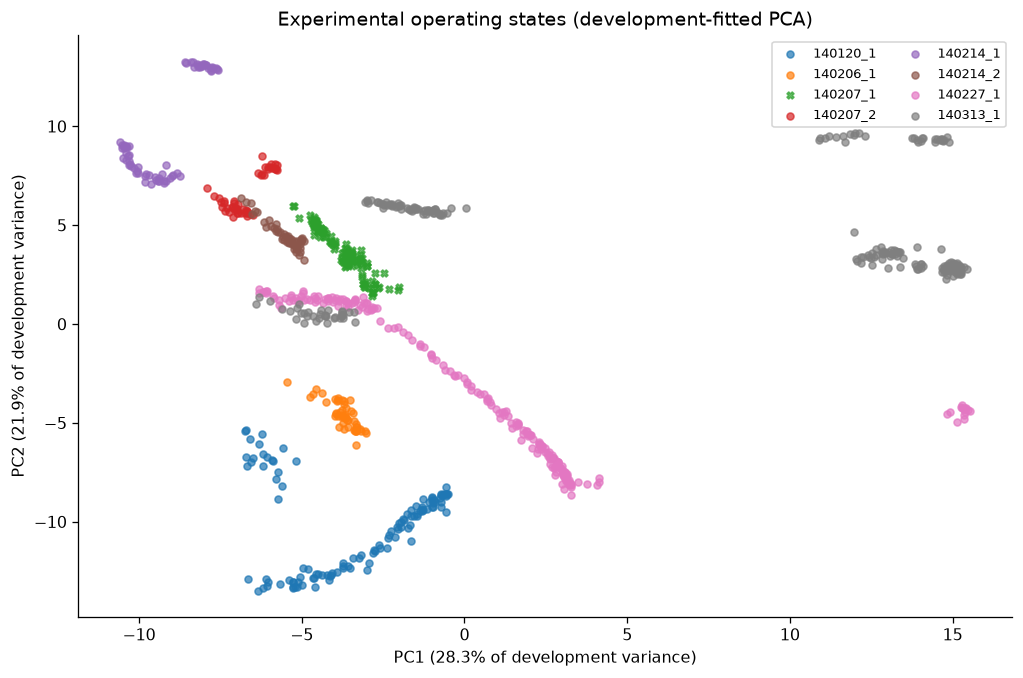

Process channels retained: 86; first two PCs explain 50.1% of development variance.


In [6]:
common=set.intersection(*(set(df.columns) for df in experiments.values()))
process_cols=[c for c in sorted(common) if re.match(r'^(AT|FT|LT|PT|PDT|TT)',c,re.I)
              and not re.search(r'AT400',c,re.I)
              and all(pd.api.types.is_numeric_dtype(experiments[r][c]) for r in RUNS)]
development=[r for r in RUNS if r!=TEST_RUN]
train=pd.concat([experiments[r][process_cols] for r in development],ignore_index=True)
usable=[c for c in process_cols if train[c].notna().mean()>=.95 and train[c].std()>1e-10]
train_median=train[usable].median()
Xtrain=train[usable].fillna(train_median).to_numpy(dtype=float)
scaler=RobustScaler().fit(Xtrain)
Ztrain=np.clip(scaler.transform(Xtrain),-15,15)
pca=PCA(n_components=2,random_state=42).fit(Ztrain)
fig,ax=plt.subplots(figsize=(9,6))
for run in RUNS:
    X=experiments[run][usable].fillna(train_median).to_numpy(dtype=float)
    coords=pca.transform(np.clip(scaler.transform(X),-15,15))
    ax.scatter(coords[:,0],coords[:,1],s=19,alpha=.7,label=run,marker='X' if run==TEST_RUN else 'o')
ax.set(xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.1%} of development variance)',
       ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.1%} of development variance)',
       title='Experimental operating states (development-fitted PCA)')
ax.legend(fontsize=8,ncol=2);figure('04_pca_operating_states',fig)
print(f'Process channels retained: {len(usable)}; first two PCs explain {sum(pca.explained_variance_ratio_):.1%} of development variance.')

## 7. Quantifying between-experiment operating-state separation

Two complementary distances are calculated in the scaled process-feature space. The heatmap compares **experiment median states**, describing differences between typical operating points. The nearest-record distance instead compares each observation with its closest observation in another experiment, capturing local proximity that medians cannot reveal. For the reserved experiment, the reference pool contains only development experiments; for a development experiment, its own observations are excluded.

Distances are normalized by the square root of the number of process channels for comparability. They are descriptive geometric measures, not probabilities of generalization.

Because the 86 process channels can be correlated, Euclidean distances may count related process variations more than once. Accordingly, these values are interpreted as **scaled multivariate operating-state distances**, rather than definitive physical similarity or a calibrated measure of operating-regime coverage.

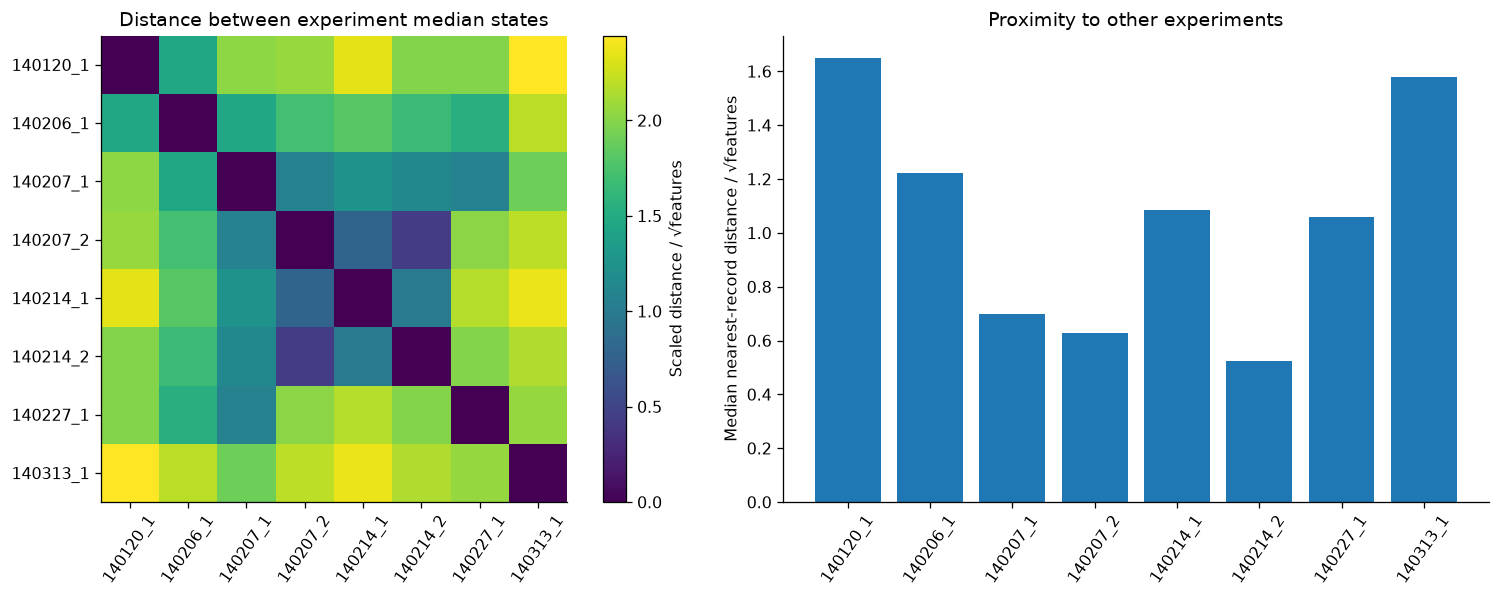

,median_nearest_other_run,p90_nearest_other_run
experiment,,
140120_1,1.650,2.171
140206_1,1.224,1.671
140207_1,0.701,1.339
140207_2,0.629,0.735
140214_1,1.084,1.240
140214_2,0.523,0.848
140227_1,1.061,1.532
140313_1,1.580,2.174


In [7]:
from sklearn.neighbors import NearestNeighbors
scaled={r:np.clip(scaler.transform(experiments[r][usable].fillna(train_median).to_numpy(dtype=float)),-15,15) for r in RUNS}
centers=np.stack([np.median(scaled[r],axis=0) for r in RUNS])
D=pairwise_distances(centers)/np.sqrt(len(usable))
nearest=[]
for run in RUNS:
    reference_runs = [q for q in development if q != run]
    others=np.concatenate([scaled[q] for q in reference_runs],axis=0)
    nn=NearestNeighbors(n_neighbors=1).fit(others)
    dist=nn.kneighbors(scaled[run],return_distance=True)[0].ravel()/np.sqrt(len(usable))
    nearest.append({'experiment':run,'median_nearest_other_run':np.median(dist),'p90_nearest_other_run':np.quantile(dist,.9)})
fig,axes=plt.subplots(1,2,figsize=(14,5.3))
im=axes[0].imshow(D,cmap='viridis');axes[0].set(xticks=range(8),xticklabels=RUNS,yticks=range(8),yticklabels=RUNS,title='Distance between experiment median states')
axes[0].tick_params(axis='x',rotation=55);fig.colorbar(im,ax=axes[0],label='Scaled distance / √features')
novelty=pd.DataFrame(nearest).set_index('experiment').reindex(RUNS)
axes[1].bar(np.arange(8),novelty.median_nearest_other_run)
axes[1].set(xticks=range(8),xticklabels=RUNS,ylabel='Median nearest-record distance / √features',title='Proximity to other experiments')
axes[1].tick_params(axis='x',rotation=55)
figure('05_operating_state_separation',fig)
display(novelty.round(3));novelty.to_csv(OUT/'operating_state_proximity.csv')

**Interpretation.** Between-experiment separation is heterogeneous: some runs have close counterparts, while others occupy more isolated regions of the measured process space. The operating map also shows that the reserved experiment's L/G values overlap those of some development experiments, so a claim that it is entirely outside the development operating envelope would be unwarranted. Comparing both physical coordinates and multivariate nearest-record distances is useful for choosing **experiment-level validation folds that cover a range of operating conditions**, rather than basing conclusions on a single test trajectory.

## 8. Findings relevant to model design

**Sampling and temporal context.** Process measurements arrive at roughly 43-second intervals, but the rotating analyzer revisits a given location after approximately 12.23 minutes. Sequence construction should respect experiment boundaries and represent historical CO₂ observations through **location identity, availability masks, and elapsed time since measurement**. History lengths around one analyzer cycle have a physical interpretation and can be compared empirically.

**Target structure.** The six absorber locations differ in both concentration magnitude and observed coverage. A location-aware prediction head and per-location performance summaries are therefore appropriate. Observed and reconstructed target values should remain distinguishable, and the documented L1 carryover requires the paper-consistent L1 convention.

**Operating conditions.** The L/G–inlet-CO₂ map describes physically meaningful variation in absorber loading, while PCA and nearest-record distances describe broader multivariate differences. Their combined evidence supports **holding out entire experiments during validation** and examining performance by operating regime, without assuming that similarity in one flow ratio guarantees similarity across all process variables.

### Measurement provenance

The concentration analysis uses observed `AT400` values and the recorded sampling-location labels. The L/G calculation follows the supplied MATLAB mechanistic model with explicit unit conversion. PCA scaling is fitted using development experiments only. Figures and summary tables are written to `outputs/data_exploration/`.

**Source:** Zhuang *et al.* (2022), *A hybrid data-driven and mechanistic model soft sensor for estimating CO₂ concentrations for a carbon capture pilot plant*, *Computers in Industry*, 143, 103747; supplied `results_generation.m` and `steady_state.xlsx`.